# CareerPrep AI — Interview Readiness & Practice Questions

## Objective
Calculate a student's overall interview readiness score based on target career requirements and serve tailored interview practice questions for their target role and skill gaps.

## Feature Workflow
1. Calculate overall Interview Readiness Score (0–100%).
2. Categorize readiness level (e.g., Needs Preparation, Interview Ready, Highly Competitive).
3. Map interview practice questions to specific technical skills and career paths.
4. Filter and display customized questions focusing on the student's highest gap areas.

## Technology
- Python
- Jupyter Notebook
- pandas (for structuring question banks)

In [1]:
# CareerPrep AI
# Step 1: Calculate Interview Readiness Score and Status

# Target career requirements (reused from our core system)
career_requirements = {
    "Python Developer": {
        "Python": 80,
        "SQL": 60,
        "Data Structures": 70,
        "Git and GitHub": 60,
        "Problem Solving": 75
    },
    "Full Stack Developer": {
        "HTML and CSS": 80,
        "JavaScript": 80,
        "Python": 60,
        "SQL": 65,
        "Git and GitHub": 60
    },
    "Data Scientist": {
        "Python": 80,
        "SQL": 70,
        "Statistics": 80,
        "Machine Learning": 75,
        "Data Visualization": 70
    }
}

def calculate_interview_readiness(student_profile, career_requirements):
    target_career = student_profile["target_career"]
    required_skills = career_requirements.get(target_career, {})
    current_skills = student_profile["current_skills"]
    
    total_required = sum(required_skills.values())
    total_achieved = 0
    
    for skill, target in required_skills.items():
        current = current_skills.get(skill, 0)
        # Cap achieved score at target score so over-proficiency in one skill doesn't inflate readiness
        total_achieved += min(current, target)
        
    readiness_percentage = round((total_achieved / total_required) * 100, 1)
    
    # Determine Readiness Tier
    if readiness_percentage >= 85:
        status = "Highly Competitive 🌟"
    elif readiness_percentage >= 70:
        status = "Interview Ready 👍"
    elif readiness_percentage >= 50:
        status = "Needs Practice 📈"
    else:
        status = "Beginner Level 🛠️"
        
    return readiness_percentage, status

# Test profiles
shivangi_profile = {
    "name": "Shivangi",
    "target_career": "Python Developer",
    "current_skills": {
        "Python": 60,
        "SQL": 40,
        "Data Structures": 30,
        "Git and GitHub": 50,
        "Problem Solving": 50
    }
}

khushi_profile = {
    "name": "Khushi",
    "target_career": "Python Developer",
    "current_skills": {
        "Python": 80,
        "SQL": 60,
        "Data Structures": 70,
        "Git and GitHub": 60,
        "Problem Solving": 75
    }
}

# Run tests
for student in [shivangi_profile, khushi_profile]:
    score, status = calculate_interview_readiness(student, career_requirements)
    print(f"Student: {student['name']}")
    print(f"Target Career: {student['target_career']}")
    print(f"Interview Readiness Score: {score}%")
    print(f"Status: {status}\n" + "-"*40)

Student: Shivangi
Target Career: Python Developer
Interview Readiness Score: 66.7%
Status: Needs Practice 📈
----------------------------------------
Student: Khushi
Target Career: Python Developer
Interview Readiness Score: 100.0%
Status: Highly Competitive 🌟
----------------------------------------


In [2]:
# CareerPrep AI
# Step 2: Question Bank and Targeted Question Recommendation Engine

# Question bank organized by technical skill
question_bank = {
    "Python": [
        "What is the difference between list and tuple in Python?",
        "How does memory management work in Python (garbage collection)?",
        "Explain decorators and give a practical use case."
    ],
    "SQL": [
        "What is the difference between WHERE and HAVING clauses?",
        "Explain INNER JOIN vs LEFT JOIN with an example.",
        "What are database indexes and how do they improve query performance?"
    ],
    "Data Structures": [
        "What is the time complexity of searching in a Hash Map vs a Binary Search Tree?",
        "How do you detect a cycle in a Linked List?",
        "Explain the difference between a Stack and a Queue with real-world examples."
    ],
    "Git and GitHub": [
        "What is the difference between git merge and git rebase?",
        "How do you resolve a merge conflict in Git?",
        "What does git pull do under the hood?"
    ],
    "Problem Solving": [
        "How do you approach optimizing an algorithm with dynamic programming?",
        "Explain the two-pointer approach and when you would use it."
    ]
}

def generate_interview_practice(student_profile, career_requirements):
    # Calculate gaps first
    target_career = student_profile["target_career"]
    required_skills = career_requirements.get(target_career, {})
    current_skills = student_profile["current_skills"]
    
    gaps = {}
    for skill, target in required_skills.items():
        current = current_skills.get(skill, 0)
        gap = max(0, target - current)
        if gap > 0:
            gaps[skill] = gap
            
    # Sort gaps from highest priority to lowest
    sorted_gaps = sorted(gaps.items(), key=lambda item: item[1], reverse=True)
    
    print(f"==================================================")
    print(f" CUSTOMIZED INTERVIEW PREPARATION: {student_profile['name'].upper()}")
    print(f" Target Role: {target_career}")
    print(f"==================================================\n")
    
    if not sorted_gaps:
        print("🎉 Great job! You have met all target proficiencies. Here are general practice questions:\n")
        # Serve 1 question from each required skill
        for skill in required_skills:
            if skill in question_bank:
                print(f"📌 {skill}:")
                print(f"   Q: {question_bank[skill][0]}\n")
        return

    print("🎯 Practice Questions Focused on Your Skill Gaps:\n")
    for skill, gap in sorted_gaps:
        if skill in question_bank:
            print(f"🔹 {skill} (Gap: {gap}%):")
            # Serve top 2 questions for high-priority gap skills
            questions = question_bank[skill][:2]
            for q in questions:
                print(f"   • {q}")
            print()

# Generate questions for Shivangi
generate_interview_practice(shivangi_profile, career_requirements)

 CUSTOMIZED INTERVIEW PREPARATION: SHIVANGI
 Target Role: Python Developer

🎯 Practice Questions Focused on Your Skill Gaps:

🔹 Data Structures (Gap: 40%):
   • What is the time complexity of searching in a Hash Map vs a Binary Search Tree?
   • How do you detect a cycle in a Linked List?

🔹 Problem Solving (Gap: 25%):
   • How do you approach optimizing an algorithm with dynamic programming?
   • Explain the two-pointer approach and when you would use it.

🔹 Python (Gap: 20%):
   • What is the difference between list and tuple in Python?
   • How does memory management work in Python (garbage collection)?

🔹 SQL (Gap: 20%):
   • What is the difference between WHERE and HAVING clauses?
   • Explain INNER JOIN vs LEFT JOIN with an example.

🔹 Git and GitHub (Gap: 10%):
   • What is the difference between git merge and git rebase?
   • How do you resolve a merge conflict in Git?



In [1]:
# Step 3: Interview Answer Evaluation

def evaluate_answer(answer):
    if len(answer.strip()) == 0:
        return 0, "No answer provided"

    word_count = len(answer.split())

    if word_count < 10:
        return 30, "Needs improvement"

    elif word_count < 25:
        return 60, "Average answer"

    else:
        return 80, "Good answer"


print("Answer evaluation function created successfully!")

Answer evaluation function created successfully!


In [2]:
# Step 4: Test the answer evaluation function

test_answers = [
    "Python is a programming language.",
    "Python supports different data structures such as lists and tuples.",
    "Python is a high-level programming language. It supports object-oriented programming, dynamic typing and multiple data structures."
]

for i, answer in enumerate(test_answers, start=1):
    score, feedback = evaluate_answer(answer)

    print(f"Answer {i}: {answer}")
    print(f"Score: {score}%")
    print(f"Feedback: {feedback}")
    print("-" * 40)

Answer 1: Python is a programming language.
Score: 30%
Feedback: Needs improvement
----------------------------------------
Answer 2: Python supports different data structures such as lists and tuples.
Score: 60%
Feedback: Average answer
----------------------------------------
Answer 3: Python is a high-level programming language. It supports object-oriented programming, dynamic typing and multiple data structures.
Score: 60%
Feedback: Average answer
----------------------------------------


In [3]:
# Step 5: Keyword-Based Answer Evaluation

def evaluate_answer_with_keywords(answer, expected_keywords):

    answer = answer.lower()

    matched_keywords = []

    for keyword in expected_keywords:
        if keyword.lower() in answer:
            matched_keywords.append(keyword)

    if len(expected_keywords) == 0:
        return 0, matched_keywords

    score = round((len(matched_keywords) / len(expected_keywords)) * 100)

    return score, matched_keywords


# Test the evaluator
answer = "Python is a high-level programming language that supports object-oriented programming."

keywords = [
    "high-level",
    "programming language",
    "object-oriented",
    "dynamic typing"
]

score, matched = evaluate_answer_with_keywords(answer, keywords)

print("Evaluation Score:", score, "%")
print("Matched Keywords:", matched)
print("Missing Keywords:", [k for k in keywords if k not in matched])

Evaluation Score: 75 %
Matched Keywords: ['high-level', 'programming language', 'object-oriented']
Missing Keywords: ['dynamic typing']


In [4]:
# Step 6: Interactive Interview Answer

question = "What is Python?"

expected_keywords = [
    "high-level",
    "programming language",
    "object-oriented",
    "dynamic typing"
]

print("INTERVIEW QUESTION:")
print(question)

student_answer = input("\nEnter your answer: ")

score, matched = evaluate_answer_with_keywords(
    student_answer,
    expected_keywords
)

missing = [k for k in expected_keywords if k not in matched]

print("\nINTERVIEW EVALUATION")
print("Score:", score, "%")
print("Matched Keywords:", matched)
print("Missing Keywords:", missing)

INTERVIEW QUESTION:
What is Python?



Enter your answer:  Python is a high-level programming language. It supports object-oriented programming and dynamic typing.



INTERVIEW EVALUATION
Score: 100 %
Matched Keywords: ['high-level', 'programming language', 'object-oriented', 'dynamic typing']
Missing Keywords: []


In [5]:
# Step 7: Complete Interview Practice Session

interview_questions = [
    {
        "question": "What is Python?",
        "keywords": ["high-level", "programming language", "object-oriented", "dynamic typing"]
    },
    {
        "question": "What is the difference between a list and a tuple?",
        "keywords": ["mutable", "immutable", "list", "tuple"]
    },
    {
        "question": "What is SQL used for?",
        "keywords": ["database", "query", "data", "manage"]
    }
]

scores = []

print("========================================")
print("       CAREERPREP AI INTERVIEW")
print("========================================")

for i, item in enumerate(interview_questions, start=1):

    print(f"\nQuestion {i}: {item['question']}")

    answer = input("Your answer: ")

    score, matched = evaluate_answer_with_keywords(
        answer,
        item["keywords"]
    )

    scores.append(score)

    print("Score:", score, "%")
    print("Matched keywords:", matched)
    print("-" * 40)

# Calculate overall performance
overall_score = round(sum(scores) / len(scores), 2)

print("\n========================================")
print("       FINAL INTERVIEW REPORT")
print("========================================")

print("Questions Attempted:", len(scores))
print("Overall Interview Score:", overall_score, "%")

if overall_score >= 85:
    print("Performance: Excellent")
elif overall_score >= 70:
    print("Performance: Good")
elif overall_score >= 50:
    print("Performance: Average")
else:
    print("Performance: Needs Improvement")

       CAREERPREP AI INTERVIEW

Question 1: What is Python?


Your answer:  Python is a high-level, interpreted programming language. It supports object-oriented programming and dynamic typing.


Score: 100 %
Matched keywords: ['high-level', 'programming language', 'object-oriented', 'dynamic typing']
----------------------------------------

Question 2: What is the difference between a list and a tuple?


Your answer:  A list is mutable, which means we can modify its elements after creation. A tuple is immutable, which means we cannot modify its elements after creation.


Score: 100 %
Matched keywords: ['mutable', 'immutable', 'list', 'tuple']
----------------------------------------

Question 3: What is SQL used for?


Your answer:  SQL is used to store, retrieve, manage and manipulate data in relational databases.


Score: 75 %
Matched keywords: ['database', 'data', 'manage']
----------------------------------------

       FINAL INTERVIEW REPORT
Questions Attempted: 3
Overall Interview Score: 91.67 %
Performance: Excellent


In [6]:
# Step 8: Store Interview Results

interview_result = {
    "student_name": "Shivangi",
    "target_career": "Python Developer",
    "questions_attempted": len(scores),
    "individual_scores": scores,
    "overall_score": overall_score,
    "performance": (
        "Excellent" if overall_score >= 85
        else "Good" if overall_score >= 70
        else "Average" if overall_score >= 50
        else "Needs Improvement"
    )
}

print("Interview Results Saved Successfully!\n")

for key, value in interview_result.items():
    print(f"{key}: {value}")

Interview Results Saved Successfully!

student_name: Shivangi
target_career: Python Developer
questions_attempted: 3
individual_scores: [100, 100, 75]
overall_score: 91.67
performance: Excellent


In [7]:
# Step 9: Create Interview Results Database

interview_database = []

# Add Shivangi's interview result
interview_database.append(interview_result)

# Display all stored interview records
print("CAREERPREP AI - INTERVIEW DATABASE")
print("=" * 45)

for student in interview_database:
    print("Student:", student["student_name"])
    print("Career:", student["target_career"])
    print("Overall Score:", student["overall_score"], "%")
    print("Performance:", student["performance"])
    print("-" * 45)

print("Total Interview Records:", len(interview_database))


CAREERPREP AI - INTERVIEW DATABASE
Student: Shivangi
Career: Python Developer
Overall Score: 91.67 %
Performance: Excellent
---------------------------------------------
Total Interview Records: 1


In [8]:
# Step 10: Add a second student record

khushi_result = {
    "student_name": "Khushi",
    "target_career": "Python Developer",
    "questions_attempted": 3,
    "individual_scores": [80, 75, 90],
    "overall_score": 81.67,
    "performance": "Good"
}

# Add Khushi's result to the database
interview_database.append(khushi_result)

# Display updated database
print("UPDATED INTERVIEW DATABASE")
print("=" * 45)

for student in interview_database:
    print("Student:", student["student_name"])
    print("Career:", student["target_career"])
    print("Overall Score:", student["overall_score"], "%")
    print("Performance:", student["performance"])
    print("-" * 45)

print("Total Interview Records:", len(interview_database))


UPDATED INTERVIEW DATABASE
Student: Shivangi
Career: Python Developer
Overall Score: 91.67 %
Performance: Excellent
---------------------------------------------
Student: Khushi
Career: Python Developer
Overall Score: 81.67 %
Performance: Good
---------------------------------------------
Total Interview Records: 2


Enter student name to search:  Shivangi



STUDENT INTERVIEW REPORT
Name: Shivangi
Career: Python Developer
Questions Attempted: 3
Individual Scores: [100, 100, 75]
Overall Score: 91.67 %
Performance: Excellent


In [10]:
# Step 12: Compare Student Performance

print("STUDENT PERFORMANCE COMPARISON")
print("=" * 45)

for student in interview_database:
    print(
        f"{student['student_name']}: "
        f"{student['overall_score']}%"
    )

# Find the highest-scoring student
top_student = max(
    interview_database,
    key=lambda student: student["overall_score"]
)

print("\nTOP PERFORMER")
print("=" * 45)
print("Name:", top_student["student_name"])
print("Score:", top_student["overall_score"], "%")
print("Performance:", top_student["performance"])


STUDENT PERFORMANCE COMPARISON
Shivangi: 91.67%
Khushi: 81.67%

TOP PERFORMER
Name: Shivangi
Score: 91.67 %
Performance: Excellent


ModuleNotFoundError: No module named 'matplotlib'

In [13]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


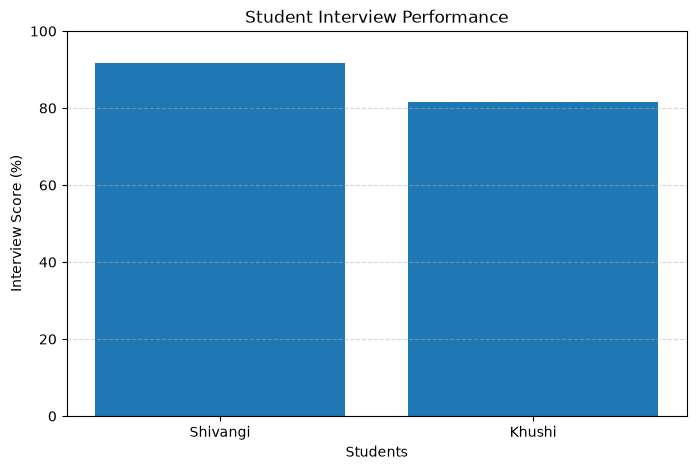

In [15]:
# Step 13: Visualize Student Interview Performance

import matplotlib.pyplot as plt

student_names = [
    student["student_name"]
    for student in interview_database
]

student_scores = [
    student["overall_score"]
    for student in interview_database
]

plt.figure(figsize=(8, 5))

plt.bar(student_names, student_scores)

plt.title("Student Interview Performance")
plt.xlabel("Students")
plt.ylabel("Interview Score (%)")

plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.show()

In [16]:
# Step 14: Import SQLite

import sqlite3

print("SQLite imported successfully!")

SQLite imported successfully!


In [17]:
# Step 15: Create CareerPrep AI Database

connection = sqlite3.connect("careerprep_ai.db")

cursor = connection.cursor()

print("CareerPrep AI database created successfully!")

CareerPrep AI database created successfully!


In [18]:
# Step 16: Create Interview Results Table

cursor.execute("""
CREATE TABLE IF NOT EXISTS interview_results (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    student_name TEXT,
    target_career TEXT,
    questions_attempted INTEGER,
    individual_scores TEXT,
    overall_score REAL,
    performance TEXT
)
""")

connection.commit()

print("Interview results table created successfully!")

Interview results table created successfully!


In [19]:
# Step 17: Save Interview Results in SQLite

for student in interview_database:

    cursor.execute("""
    INSERT INTO interview_results
    (student_name, target_career, questions_attempted,
     individual_scores, overall_score, performance)
    VALUES (?, ?, ?, ?, ?, ?)
    """, (
        student["student_name"],
        student["target_career"],
        student["questions_attempted"],
        str(student["individual_scores"]),
        student["overall_score"],
        student["performance"]
    ))

connection.commit()

print("All interview results saved in SQLite successfully!")

All interview results saved in SQLite successfully!


In [20]:
# Step 18: View Saved Interview Results

cursor.execute("SELECT * FROM interview_results")

saved_records = cursor.fetchall()

print("CAREERPREP AI - SAVED DATABASE RECORDS")
print("=" * 50)

for record in saved_records:
    print("ID:", record[0])
    print("Student:", record[1])
    print("Career:", record[2])
    print("Questions Attempted:", record[3])
    print("Individual Scores:", record[4])
    print("Overall Score:", record[5], "%")
    print("Performance:", record[6])
    print("-" * 50)

print("Total Records Saved:", len(saved_records))

CAREERPREP AI - SAVED DATABASE RECORDS
ID: 1
Student: Shivangi
Career: Python Developer
Questions Attempted: 3
Individual Scores: [100, 100, 75]
Overall Score: 91.67 %
Performance: Excellent
--------------------------------------------------
ID: 2
Student: Khushi
Career: Python Developer
Questions Attempted: 3
Individual Scores: [80, 75, 90]
Overall Score: 81.67 %
Performance: Good
--------------------------------------------------
Total Records Saved: 2


In [21]:
connection.close()

print("Database connection closed successfully!")

Database connection closed successfully!


In [22]:
connection = sqlite3.connect("careerprep_ai.db")
cursor = connection.cursor()

cursor.execute("SELECT COUNT(*) FROM interview_results")
total_records = cursor.fetchone()[0]

print("Total interview records stored:", total_records)

Total interview records stored: 2


In [23]:
import pandas as pd

cursor.execute("SELECT * FROM interview_results")

columns = [
    "ID",
    "Student Name",
    "Target Career",
    "Questions Attempted",
    "Individual Scores",
    "Overall Score",
    "Performance"
]

records = cursor.fetchall()

interview_df = pd.DataFrame(records, columns=columns)

interview_df

ModuleNotFoundError: No module named 'pandas'

In [24]:
%pip install pandas

   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   -------- ------------------------------- 2.4/10.9 MB 11.3 MB/s eta 0:00:01
   ----------------- ---------------------- 4.7/10.9 MB 11.5 MB/s eta 0:00:01
   -------------------------- ------------- 7.3/10.9 MB 11.6 MB/s eta 0:00:01
   ----------------------------------- ---- 9.7/10.9 MB 11.6 MB/s eta 0:00:01
   ---------------------------------------- 10.9/10.9 MB 10.7 MB/s  0:00:01
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [25]:
import pandas as pd

cursor.execute("SELECT * FROM interview_results")

columns = [
    "ID",
    "Student Name",
    "Target Career",
    "Questions Attempted",
    "Individual Scores",
    "Overall Score",
    "Performance"
]

records = cursor.fetchall()

interview_df = pd.DataFrame(records, columns=columns)

interview_df


,ID,Student Name,Target Career,Questions Attempted,Individual Scores,Overall Score,Performance
0,1,Shivangi,Python Developer,3,"[100, 100, 75]",91.67,Excellent
1,2,Khushi,Python Developer,3,"[80, 75, 90]",81.67,Good


In [26]:
connection.close()

print("Database connection closed successfully!")

Database connection closed successfully!
